# Global ePSF Model — PSFMachine Polar B-Spline Method

This notebook demonstrates how to build a global ePSF model for a single Roman WFI
detector using the `roman_epsf.psfmachine` module, which implements a
[PSFMachine](https://github.com/SSDataLab/psfmachine)-inspired polar B-spline model
using pure NumPy and SciPy.

**Key idea:** instead of stacking and iterating over individual star stamps
(EPSFBuilder approach), every pixel in every star cutout is treated as an
independent data point: `(Δcol, Δrow, normalised flux)`.  A single tensor-product
B-spline in polar coordinates is then fit simultaneously to all these pixels.  This
makes the model robust to faint stars, slight blending, and missing pixels.

**Workflow:**
1. Authenticate with MAST and query L2/L4 products.
2. Open the calibrated detector image (`.asdf`) and source catalog (`.parquet`).
3. Select stars with *looser* criteria (fainter, less isolated) via `select_stars`.
4. Assemble pixel arrays: `(delta_col, delta_row, norm_flux, star_idx)` with `build_pixel_arrays`.
5. Fit the polar B-spline ePSF with `fit_epsf`.
6. Visualise the 2D model on an oversampled grid.
7. Save the B-spline coefficients and an image to FITS, then reload.

**Requirements:** `roman-epsf` installed (with the `com` extras from `roman-cuts`).

```
pip install -e ../  # from this notebooks/ directory
```

## 0. Imports and MAST authentication

In [ ]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from astropy.visualization import simple_norm
from dotenv import load_dotenv
from astroquery.mast import MastMissions, Observations
import pandas as pd

# roman-cuts data-access layer
from roman_cuts.com import query_mast_files
from roman_cuts.com.io import _open_asdf, open_parquet

# roman-epsf — shared star selection + psfmachine method
from roman_epsf import select_stars
from roman_epsf.psfmachine import (
    build_pixel_arrays,
    fit_epsf,
    evaluate_epsf,
    refine_centroids,
    save_model,
    load_model,
    save_image,
)

In [ ]:
load_dotenv("/teams/romcom/data/jmartinez/my_crds_path.env", override=True)
token = os.environ.get("MAST_API_TOKEN", "")

mission = MastMissions(mission="roman")
if token:
    mission.login(token=token)
Observations.enable_cloud_dataset()

## 1. Query and select an L2 image + L4 catalog pair

In [ ]:
pid         = 1055
detector    = 4
filter_name = "F146"

products_l2, _ = query_mast_files(
    program_id=pid, detector=detector, filter_name=filter_name,
    mission=mission, file_type="l2",
)
products_l4, _ = query_mast_files(
    program_id=pid, detector=detector, filter_name=filter_name,
    mission=mission, file_type="l4",
)

print(f"Found {len(products_l2)} L2 images and {len(products_l4)} L4 catalogs.")

asdf_filename = products_l2["filename"][10]
prefix = asdf_filename.replace("_cal.asdf", "")
matching = [f for f in products_l4["filename"] if prefix in str(f)]
parquet_filename = matching[0] if matching else products_l4["filename"][0]

print("Image  :", asdf_filename)
print("Catalog:", parquet_filename)

## 2. Load the detector image and source catalog

In [ ]:
with _open_asdf(asdf_filename, mission=mission) as af:
    data = np.asarray(af["roman"]["data"], dtype=np.float64).copy()
    dq   = np.asarray(af["roman"]["dq"]).copy() if "dq" in af["roman"] else None
    gwcs = af["roman"]["meta"]["wcs"]

print(f"Image shape: {data.shape}")

if os.path.exists(str(parquet_filename)):
    cat_df = pd.read_parquet(parquet_filename)
else:
    cat_df = open_parquet(parquet_filename, token=token)

print(f"Catalog sources: {len(cat_df)}")

## 3. Select stars — bright but not saturated

Diffraction spikes are faint azimuthal features (~1 % of the PSF peak). To measure
them reliably we prefer **brighter** stars where the spikes clear the noise floor.
Very faint stars add noise to the azimuthal signal and dilute the spike pattern in
the simultaneous fit.  We therefore use `flux_percentile_range=(50, 98)` — brighter
than the photutils path (60–99) is not needed, but much fainter is harmful.

| Parameter | EPSFBuilder | PSFMachine (previous) | PSFMachine (improved) |
|-----------|------------|----------------------|----------------------|
| `flux_percentile_range` | (60, 99) | (20, 98) | **(50, 98)** |
| `min_sep_factor` | 1.2 | 0.8 | **1.0** |

In [ ]:
cutout_size = 25

selected = select_stars(
    cat_df,
    image_shape=data.shape,
    cutout_size=cutout_size,
    flux_percentile_range=(50, 98),   # bright enough for spikes to clear noise
    min_sep_factor=1.0,               # moderate isolation
    gwcs=gwcs,
)
print(f"Selected {len(selected)} stars for PSFMachine fitting.")

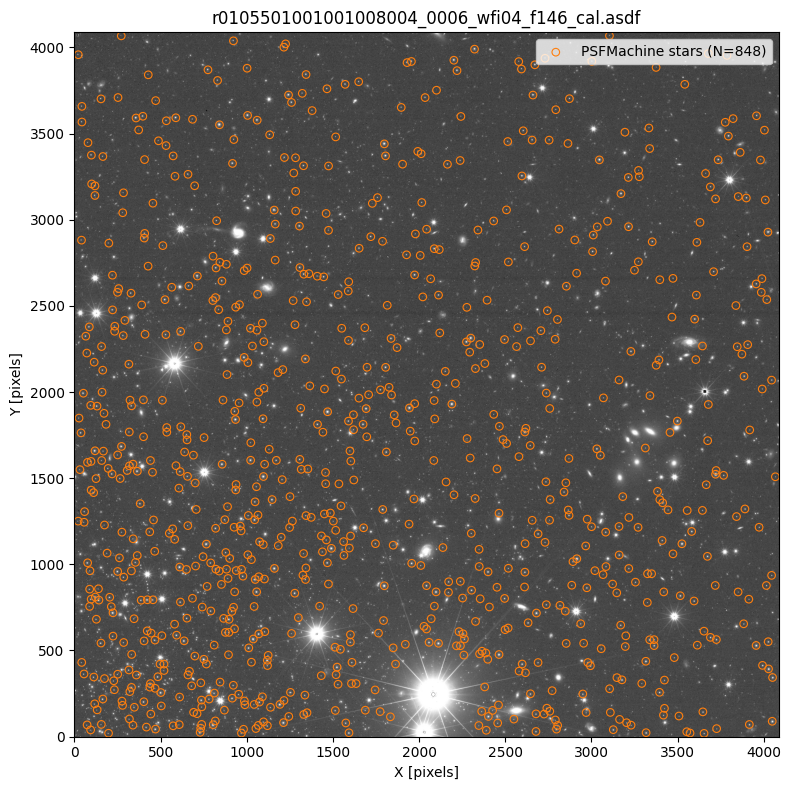

In [37]:
fig, ax = plt.subplots(figsize=(8, 8))
norm = simple_norm(data, "sqrt", percent=99.0)
ax.imshow(data, origin="lower", cmap="Greys_r", norm=norm)
ax.scatter(
    selected["x_pix"], selected["y_pix"],
    s=30, facecolors="none", edgecolors="tab:orange", linewidths=0.8,
    label=f"PSFMachine stars (N={len(selected)})",
)
ax.set_xlabel("X [pixels]")
ax.set_ylabel("Y [pixels]")
ax.set_title(asdf_filename)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 4. Build pixel arrays

`build_pixel_arrays` extracts a stamp around each selected star, optionally
subtracts a local background (estimated from the outer annulus of the stamp), and
normalises each pixel value by the star's total flux from the catalog.  The result
is four flat arrays over all pixels × all stars:

- `delta_col` — column offset from the star centre (native pixels)
- `delta_row` — row offset from the star centre (native pixels)
- `norm_flux` — background-subtracted, flux-normalised pixel value
- `star_idx`  — index of the parent star (maps each pixel back to its star)

The `background="local"` mode estimates a scalar per-stamp background from the
outermost ring of pixels before normalisation, making the method relatively
insensitive to sky gradients.

In [38]:
delta_col, delta_row, norm_flux, star_idx = build_pixel_arrays(
    data,
    dq,
    selected,
    cutout_size=cutout_size,
    background="local",    # per-stamp local background from outer stamp border
    # background=None,     # uncomment to skip background subtraction
    sigma_clip_bg=3.0,
)

n_stars_used = delta_col.shape[0]
n_pixels_per_star = delta_col.shape[1]
n_valid = int(np.sum(np.isfinite(norm_flux)))
print(f"Pixel arrays assembled:")
print(f"  Shape          : {delta_col.shape}  (n_stars × n_pixels_per_star)")
print(f"  Stars with data: {n_stars_used}")
print(f"  Pixels/star    : {n_pixels_per_star}  ({cutout_size}×{cutout_size})")
print(f"  Valid pixels   : {n_valid:,}  (non-NaN, non-masked)")

Pixel arrays assembled:
  Shape          : (848, 625)  (n_stars × n_pixels_per_star)
  Stars with data: 848
  Pixels/star    : 625  (25×25)
  Valid pixels   : 529,859  (non-NaN, non-masked)


### 4b. Inspect the raw pixel data in polar space

Plotting the normalised pixel values vs. radius (in native pixels) gives an early
sanity check: the radial profile should be a smooth, declining function.

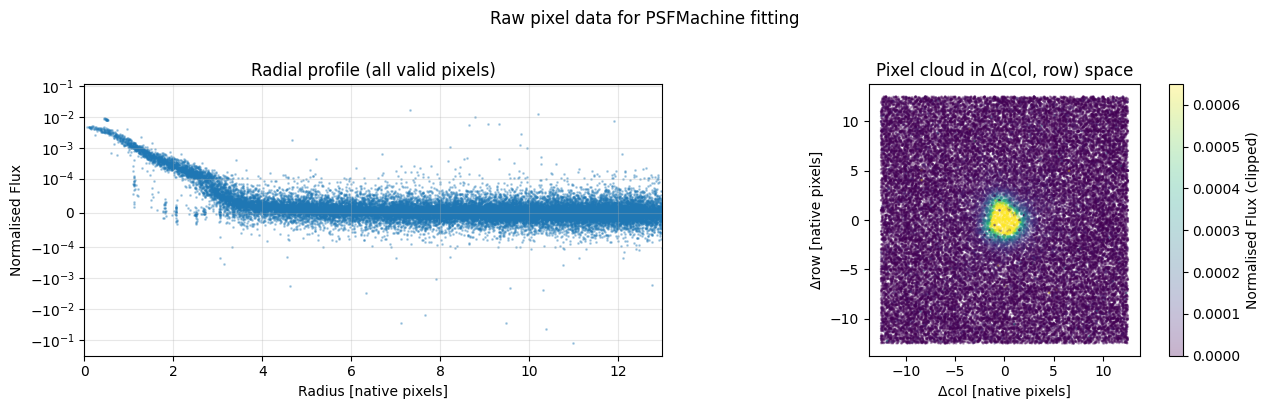

In [39]:
# Flatten 2D arrays and filter out masked (NaN) pixels
dc_flat  = delta_col.ravel()
dr_flat  = delta_row.ravel()
nf_flat  = norm_flux.ravel()
valid    = np.isfinite(nf_flat)

r_pix = np.sqrt(dc_flat**2 + dr_flat**2)

# Subsample valid pixels for legibility
rng = np.random.default_rng(0)
valid_idx = np.where(valid)[0]
idx_sub = rng.choice(valid_idx, size=min(50_000, len(valid_idx)), replace=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle("Raw pixel data for PSFMachine fitting", y=1.01)

# Scatter: r vs. norm_flux (log)
axes[0].scatter(
    r_pix[idx_sub], nf_flat[idx_sub],
    s=1, alpha=0.3, c="tab:blue", rasterized=True,
)
axes[0].set_yscale("symlog", linthresh=1e-4)
axes[0].set_xlim(0, cutout_size // 2 + 1)
axes[0].set_xlabel("Radius [native pixels]")
axes[0].set_ylabel("Normalised Flux")
axes[0].set_title("Radial profile (all valid pixels)")
axes[0].grid(True, alpha=0.3)

# 2D scatter: dc vs. dr, coloured by norm_flux
vmax = np.nanpercentile(nf_flat[idx_sub], 99)
sc = axes[1].scatter(
    dc_flat[idx_sub], dr_flat[idx_sub],
    c=np.clip(nf_flat[idx_sub], 0, vmax),
    s=1, cmap="viridis", alpha=0.3, rasterized=True,
)
plt.colorbar(sc, ax=axes[1], label="Normalised Flux (clipped)")
axes[1].set_xlabel("Δcol [native pixels]")
axes[1].set_ylabel("Δrow [native pixels]")
axes[1].set_title("Pixel cloud in Δ(col, row) space")
axes[1].set_aspect("equal")

plt.tight_layout()
plt.show()

## 5. Iterative polar B-spline ePSF fit

Three key changes from the previous (non-spike-preserving) approach:

1. **`coords="polar"`** — The polar basis separates radial profile from azimuthal
   modulation, making diffraction spikes representable as phi-variations at fixed r.
   The previous `coords="cartesian"` mode had no phi basis at all.

2. **`cut_r=1.0`** (was 3.0) — `cut_r` suppresses all azimuthal terms inside that
   radius. Roman's spikes originate at the PSF centre; with `cut_r=3.0` the entire
   inner spike was forced to be radially symmetric. Reducing to 1.0 pixel lets phi
   modulation be active almost everywhere.

3. **`refine_centroids` iteration** — The biggest missing ingredient. `EPSFBuilder`
   iterates with centroid re-fitting; a 0.1 px catalogue offset, averaged over many
   stars, completely smears azimuthal structure. We add an explicit iterative loop:
   fit → refine centroids → re-build pixel arrays → re-fit.

The loop runs 3 times. Convergence is fast because the first fit already provides a
good model for centroid refinement.

In [ ]:
N_ITER    = 3      # centroid refinement iterations
N_R_KNOTS = 12     # radial B-spline knots (sqrt-spaced from rmin to rmax)
N_PHI_KNOTS = 24   # azimuthal knots — 360°/24 = 15° angular resolution
RMIN      = 0.5    # ignore sub-half-pixel offsets (noisy)
RMAX      = 12.0   # outer model boundary (≈ cutout_size/2 − 1)
CUT_R     = 1.0    # phi modulation active for r > 1 pixel (was 3.0)
PRIOR_SIGMA = 1e3  # weak Gaussian prior

# --- Initial pixel arrays (using catalog coordinates) ----------------------
delta_col, delta_row, norm_flux, star_idx = build_pixel_arrays(
    data, dq, selected,
    cutout_size=cutout_size,
    background="local",
    sigma_clip_bg=3.0,
    norm_mode="measured",  # normalise by measured stamp flux for accuracy
)
print(f"Initial: {delta_col.shape[0]} stars, {np.sum(np.isfinite(norm_flux)):,} valid pixels")

# --- Iterative centroid refinement -----------------------------------------
selected_iter = selected.copy()
for it in range(N_ITER):
    model = fit_epsf(
        delta_col, delta_row, norm_flux,
        n_r_knots=N_R_KNOTS,
        n_phi_knots=N_PHI_KNOTS,
        rmin=RMIN,
        rmax=RMAX,
        cut_r=CUT_R,
        prior_sigma=PRIOR_SIGMA,
        coords="polar",
        log_fit=True,
    )
    if it < N_ITER - 1:
        selected_iter, delta_col, delta_row, norm_flux, star_idx = refine_centroids(
            model, selected_iter, data, dq, cutout_size,
            background="local", sigma_clip_bg=3.0,
            norm_mode="measured",
        )
        print(f"Iter {it + 1}/{N_ITER}: {delta_col.shape[0]} stars remaining")

print("\nFinal model summary:")
print(f"  Radial knots : {model.n_r_knots}  ({model.rmin:.1f} – {model.rmax:.1f} px)")
print(f"  Phi knots    : {model.n_phi_knots}")
print(f"  cut_r        : {model.cut_r:.1f} px")
print(f"  Weights shape: {model.weights.shape}")
print(f"  Pixels used  : {model.n_pixels:,}")

## 6. Evaluate on an oversampled grid

`evaluate_epsf` samples the fitted B-spline model on a regular oversampled grid,
clips negative values (optional), and normalises to unit sum (optional).  The
output is a 2D `np.ndarray` of shape `(cutout_size * oversampling,
cutout_size * oversampling)`.  It is compatible with `photutils.psf.ImagePSF`.

In [ ]:
oversampling = 4
# Full evaluation and visualization are in the combined cell below (section 7b).

## 7. Visualise the PSFMachine ePSF model

The combined cell below evaluates the model on an oversampled grid and shows:
- **Left** — 2D ePSF image (log stretch). Diffraction spikes should be visible as
  faint arms extending from the core.
- **Middle** — 1D cross-sections along X and Y.
- **Right** — Azimuthal flux profile at fixed radii. Spikes appear as narrow peaks
  above the ring mean (dashed line at 1).

### 7b. Azimuthal spike diagnostic

Plot the ePSF model as a function of angle at fixed radius to check whether the
diffraction spikes are recovered. Roman's spikes occur at specific position angles
determined by the telescope support struts. A well-recovered spike appears as a
narrow peak in the azimuthal profile above the background level.

In [ ]:
oversampling = 4

psf_img = evaluate_epsf(
    model,
    cutout_size=cutout_size,
    oversampling=oversampling,
    x_0=0.0,
    y_0=0.0,
    clip_negative=True,
    normalise=True,
)

# --- 2D ePSF image with diffraction spike check ----------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle(
    f"Roman WFI {filter_name} PID {pid} SCA {detector:02d} — Improved PSFMachine (polar, iterative)",
    y=1.01,
)

# Left: log-stretched 2D image
norm_epsf = simple_norm(psf_img, "log", percent=99.5)
im = axes[0].imshow(psf_img, norm=norm_epsf, origin="lower", cmap="viridis")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04, label="Normalised Flux")
axes[0].set_title(f"2D ePSF  (oversampling={oversampling})")
axes[0].set_xlabel("Oversampled X [px]")
axes[0].set_ylabel("Oversampled Y [px]")

# Middle: 1D cross-sections
cy, cx = np.unravel_index(np.nanargmax(psf_img), psf_img.shape)
pix_x = (np.arange(psf_img.shape[1]) - cx) / oversampling
pix_y = (np.arange(psf_img.shape[0]) - cy) / oversampling
axes[1].plot(pix_x, psf_img[cy, :], "o-", ms=3, label="Horizontal (X)")
axes[1].plot(pix_y, psf_img[:, cx], "s--", ms=3, label="Vertical (Y)")
axes[1].set_yscale("log")
axes[1].set_xlabel("Distance from centre [native pixels]")
axes[1].set_ylabel("Normalised Flux (log)")
axes[1].set_title("ePSF Cross-Sections")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Right: azimuthal profile at fixed radii to reveal spikes
phi_arr = np.linspace(-np.pi, np.pi, 360)
for r_native in [3.0, 5.0, 7.0]:
    dc_ring = r_native * np.cos(phi_arr)
    dr_ring = r_native * np.sin(phi_arr)
    flux_ring = model.evaluate(dc_ring, dr_ring)
    # Normalise each ring to its mean so different radii are comparable
    ring_mean = np.nanmean(flux_ring)
    if ring_mean > 0:
        axes[2].plot(np.degrees(phi_arr), flux_ring / ring_mean,
                     label=f"r = {r_native:.0f} px", lw=1.2)
axes[2].axhline(1.0, color="k", lw=0.7, ls="--", alpha=0.5)
axes[2].set_xlabel("Position angle [degrees]")
axes[2].set_ylabel("Flux / ring mean")
axes[2].set_title("Azimuthal profile at fixed radii\n(spikes appear as peaks above 1)")
axes[2].legend(fontsize=9)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nePSF shape: {psf_img.shape},  sum = {psf_img.sum():.6f}")

### 7b. Sub-pixel phase dependence

The PSFMachine model can be evaluated at any continuous sub-pixel offset `(x_0, y_0)`
without interpolation — the B-spline basis does this analytically.  Here we compare
the model evaluated at four different sub-pixel phases to verify that the model
captures the expected (small) positional dependence.

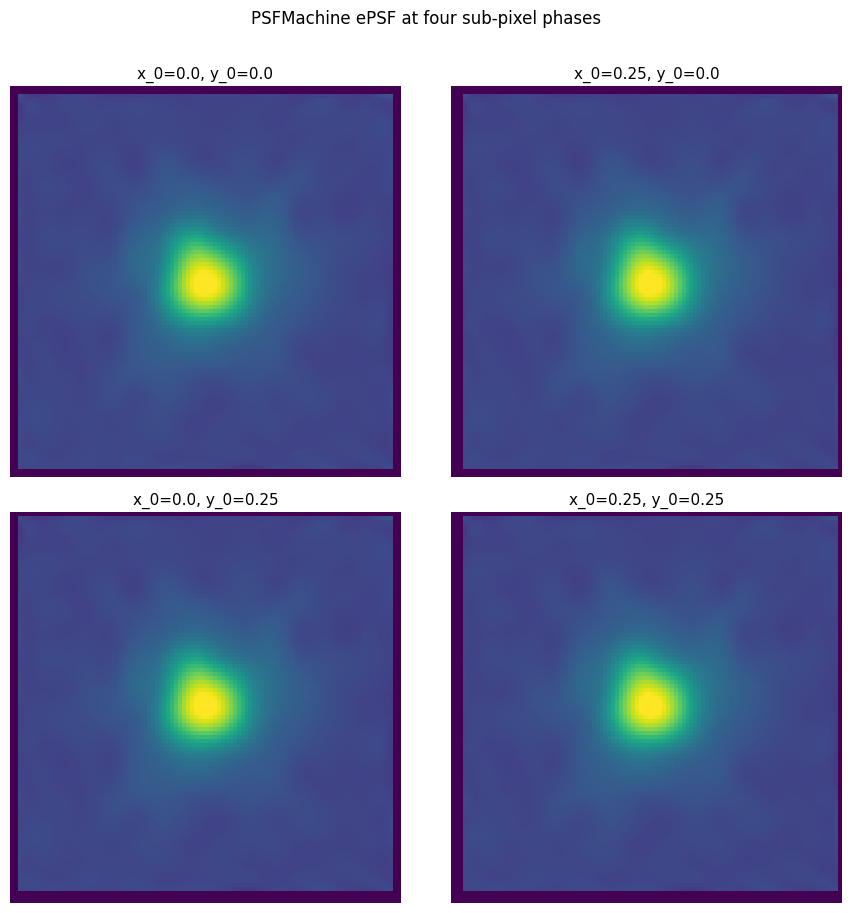

In [62]:
phases = [(0.0, 0.0), (0.25, 0.0), (0.0, 0.25), (0.25, 0.25)]

fig, axes = plt.subplots(2, 2, figsize=(9, 9))
axes = axes.ravel()

for i, (x0, y0) in enumerate(phases):
    img = evaluate_epsf(model, cutout_size=cutout_size, oversampling=oversampling,
                        x_0=x0, y_0=y0, clip_negative=True, normalise=True)
    norm_s = simple_norm(img, "log", percent=99.5)
    axes[i].imshow(img, norm=norm_s, origin="lower", cmap="viridis")
    axes[i].set_title(f"x_0={x0}, y_0={y0}", fontsize=11)
    axes[i].axis("off")

fig.suptitle("PSFMachine ePSF at four sub-pixel phases", y=1.01)
plt.tight_layout()
plt.show()

### 7c. Per-star residual inspection

For a few individual stars we compare the raw cutout to the model prediction and
plot the residual image.

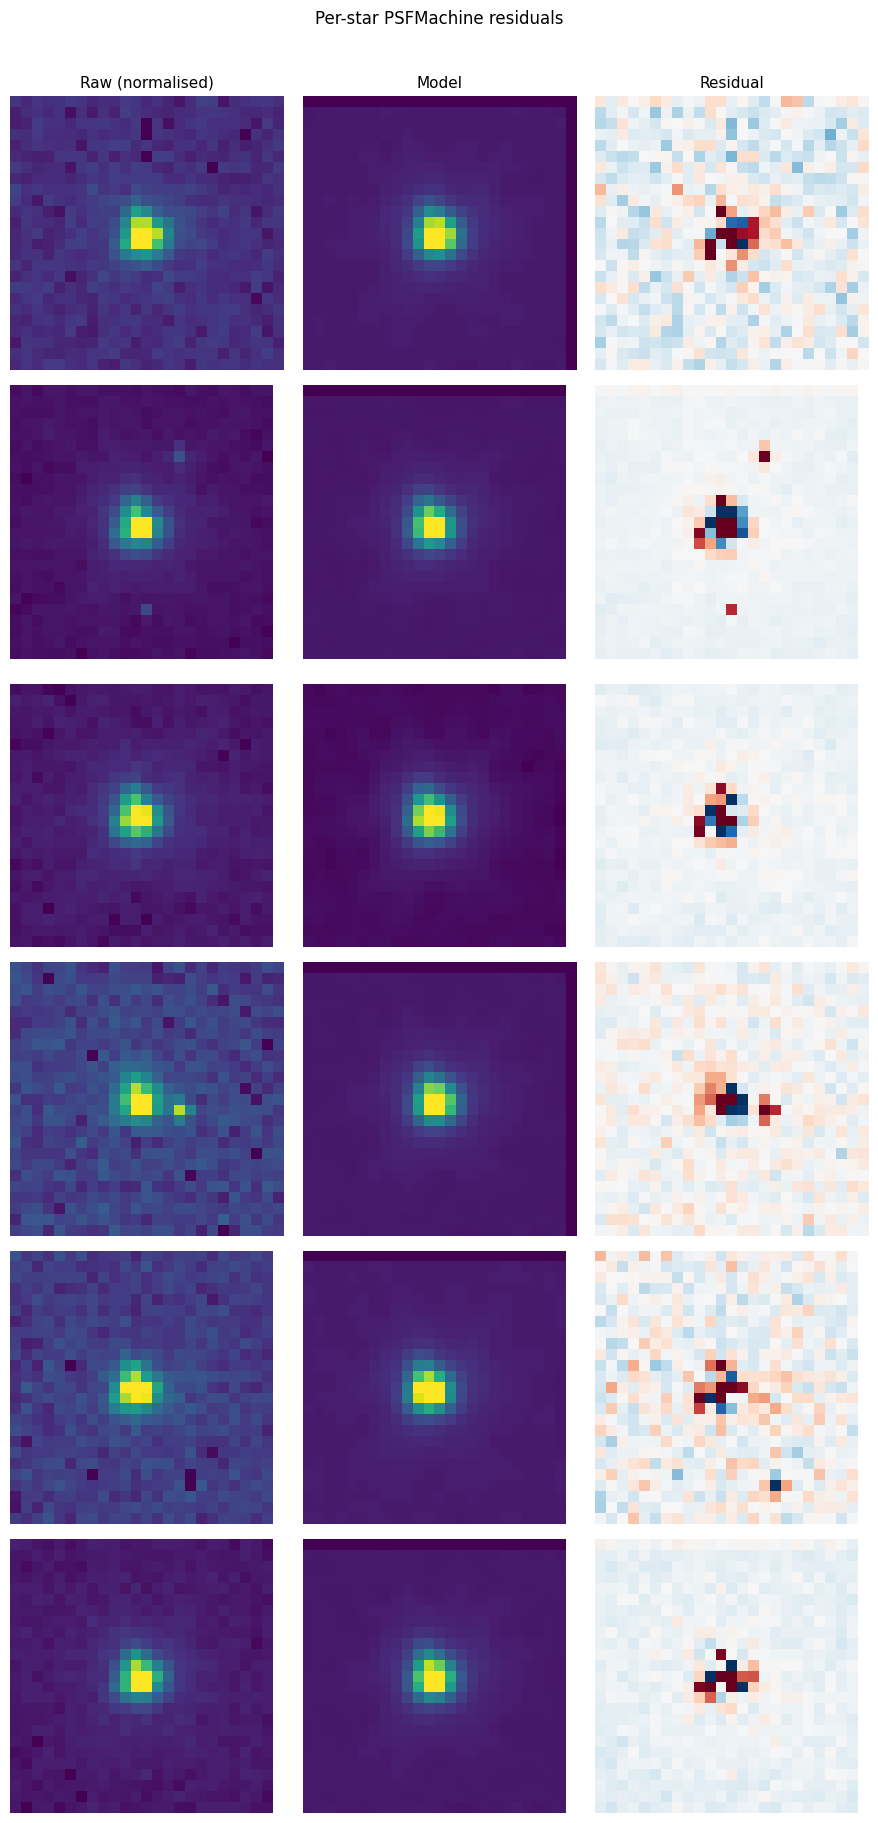

In [63]:
n_show = min(6, delta_col.shape[0])
fig, axes = plt.subplots(n_show, 3, figsize=(9, 3 * n_show))

half = cutout_size // 2

for row_i in range(n_show):
    dc_s = delta_col[row_i]      # shape (cutout_size²,)
    dr_s = delta_row[row_i]
    nf_s = norm_flux[row_i]      # NaN where masked
    valid_s = np.isfinite(nf_s)

    # Reconstruct the raw cutout on a regular grid
    raw_grid  = np.full((cutout_size, cutout_size), np.nan)
    pred_grid = np.full((cutout_size, cutout_size), np.nan)

    dc_int = (dc_s[valid_s] + half).astype(int)
    dr_int = (dr_s[valid_s] + half).astype(int)
    in_bounds = (dc_int >= 0) & (dc_int < cutout_size) & (dr_int >= 0) & (dr_int < cutout_size)

    raw_grid[dr_int[in_bounds], dc_int[in_bounds]] = nf_s[valid_s][in_bounds]
    pred_vals = model.evaluate(dc_s[valid_s][in_bounds], dr_s[valid_s][in_bounds])
    pred_grid[dr_int[in_bounds], dc_int[in_bounds]] = pred_vals

    residual = raw_grid - pred_grid
    vmax = np.nanpercentile(np.abs(residual), 99)

    norm_raw  = simple_norm(raw_grid,  "sqrt", percent=99.0)
    norm_pred = simple_norm(pred_grid, "sqrt", percent=99.0)

    axes[row_i, 0].imshow(raw_grid,  norm=norm_raw,  origin="lower", cmap="viridis")
    axes[row_i, 1].imshow(pred_grid, norm=norm_pred, origin="lower", cmap="viridis")
    axes[row_i, 2].imshow(residual,  vmin=-vmax, vmax=vmax, origin="lower", cmap="RdBu_r")

    if row_i == 0:
        for ax, title in zip(axes[row_i], ["Raw (normalised)", "Model", "Residual"]):
            ax.set_title(title, fontsize=11)
    axes[row_i, 0].set_ylabel(f"Star {star_idx[row_i]}", fontsize=9)
    for ax in axes[row_i]:
        ax.axis("off")

plt.suptitle("Per-star PSFMachine residuals", y=1.01)
plt.tight_layout()
plt.show()

## 8. Save and reload the model

### 8a. Save B-spline coefficients (compact, re-evaluable at any position)

`save_model` writes the spline weights and knot positions to a small FITS file.
The loaded model can be re-evaluated at any `(x_0, y_0)` without storing a
full oversampled image.

In [64]:
OUT_DIR = f"/teams/romcom/data/jmartinez/data/ePSF/program_{pid}/psfmachine"
os.makedirs(OUT_DIR, exist_ok=True)

model_path = f"{OUT_DIR}/roman_psm_pid{pid}_wfi{detector:02d}_{filter_name.lower()}_model.fits"

save_model(
    model,
    model_path,
    extra_header={
        "INSTRUME": "WFI",
        "DETECTOR": f"WFI{detector:02d}",
        "FILTER"  : filter_name,
        "CUTSIZE" : cutout_size,
        "ASDF_REF": str(asdf_filename),
    },
)
print(f"Model saved to: {model_path}")

Model saved to: /teams/romcom/data/jmartinez/data/ePSF/program_1055/psfmachine/roman_psm_pid1055_wfi04_f146_model.fits


In [65]:
loaded_model, loaded_hdr = load_model(model_path)

# Verify round-trip: evaluate at a few test positions
dc_test = np.array([0.0, 1.0, -1.0, 2.5, -2.5])
dr_test = np.array([0.0, 0.5,  0.5, 1.0, -1.0])

orig_vals   = model.evaluate(dc_test, dr_test)
loaded_vals = loaded_model.evaluate(dc_test, dr_test)

print("Weights match  :", np.allclose(model.weights, loaded_model.weights))
print("Evaluate match :", np.allclose(orig_vals, loaded_vals))

print("\nHeader:")
for key in ["INSTRUME", "DETECTOR", "FILTER", "NRKNOTS", "NPHIKNTS", "NSTARS", "NPIXELS"]:
    print(f"  {key:10s} = {loaded_hdr.get(key)}")

Weights match  : True
Evaluate match : True

Header:
  INSTRUME   = WFI
  DETECTOR   = WFI04
  FILTER     = F146
  NRKNOTS    = 15
  NPHIKNTS   = 0
  NSTARS     = 0
  NPIXELS    = 312485


### 8b. Save as an oversampled image (compatible with photutils)

In [66]:
image_path = f"{OUT_DIR}/roman_psm_pid{pid}_wfi{detector:02d}_{filter_name.lower()}_epsf.fits"

save_image(
    model,
    image_path,
    cutout_size=cutout_size,
    oversampling=oversampling,
    x_0=0.0,
    y_0=0.0,
    clip_negative=True,
    normalise=True,
    extra_header={
        "INSTRUME": "WFI",
        "DETECTOR": f"WFI{detector:02d}",
        "FILTER"  : filter_name,
    },
)

# Verify shape
from astropy.io import fits
with fits.open(image_path) as hdul:
    saved_img = hdul[0].data.copy()
    img_hdr   = hdul[0].header

print(f"Saved ePSF image shape: {saved_img.shape}")
print(f"Oversampling in header: {img_hdr['OVERSAMP']}")
print(f"Normalised sum: {saved_img.sum():.6f}")
print(f"Image saved to: {image_path}")

Saved ePSF image shape: (100, 100)
Oversampling in header: 4
Normalised sum: 1.000000
Image saved to: /teams/romcom/data/jmartinez/data/ePSF/program_1055/psfmachine/roman_psm_pid1055_wfi04_f146_epsf.fits


### 8c. Use the saved image as a `photutils` `ImagePSF`

The 2D FITS image written by `save_image` is compatible with
`photutils.psf.ImagePSF`: load it and evaluate just like any oversampled PSF model.

In [ ]:
from photutils.psf import ImagePSF

psf_model = ImagePSF(
    data=saved_img,
    oversampling=oversampling,
)

# Evaluate on a native-pixel stamp centred at sub-pixel position (0.3, -0.15)
yy, xx = np.mgrid[-12:13, -12:13].astype(float)
stamp = psf_model.evaluate(xx, yy, flux=1.0, x_0=0.3, y_0=-0.15)

fig, ax = plt.subplots(figsize=(5, 5))
norm_s = simple_norm(stamp, "log", percent=99.5)
ax.imshow(stamp, norm=norm_s, origin="lower", cmap="viridis")
ax.set_title("PSFMachine ePSF via photutils.ImagePSF  (x_0=0.3, y_0=-0.15)")
ax.set_xlabel("ΔX [native pixels]")
ax.set_ylabel("ΔY [native pixels]")
plt.tight_layout()
plt.show()

## Summary

| Step | Function | Key output |
|------|----------|------------|
| Star selection | `select_stars` | `selected` DataFrame |
| Pixel arrays | `build_pixel_arrays` | `(delta_col, delta_row, norm_flux, star_idx)` |
| ePSF fit | `fit_epsf` | `PSFMachineModel` |
| 2D evaluation | `evaluate_epsf` | 2D `np.ndarray` |
| Save model | `save_model` | compact FITS with B-spline weights |
| Load model | `load_model` | `PSFMachineModel` + header |
| Save image | `save_image` | photutils-compatible FITS image |

The fitted `PSFMachineModel` can be evaluated at any continuous sub-pixel position
directly — no interpolation step is needed — which is useful for drizzling or
forward-model photometry.